In [1]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image, display

In [2]:
T_end = 2*np.pi
NT = 128
ND = 600
x = np.linspace(-4, 4, ND + 1)
t = np.linspace(0, T_end, NT + 1)
dx = x[1] - x[0]
dt = T_end / NT

print("Positions:", x.shape, "dx:", dx)
print("Times:", t.shape, "dt:", dt)

Positions: (601,) dx: 0.013333333333333197
Times: (129,) dt: 0.04908738521234052


In [3]:
TSN = 200329351
d=51
s=3
def gaussian(x, center, alpha, k0):
    return (alpha / np.pi)**0.25 * np.exp(
        -alpha / 2 * (x - center)**2# + 1j * k0 * (x - center)
    )

alpha = 2
center = (-1)**(s) * (0.5+d/200)
k0 = 0.0
psi0 = gaussian(x, center, alpha, k0)
P0 = np.abs(psi0)**2
norm0 = dx * np.sum(P0)
print("Initial norm:", norm0)

Initial norm: 0.9999999999607603


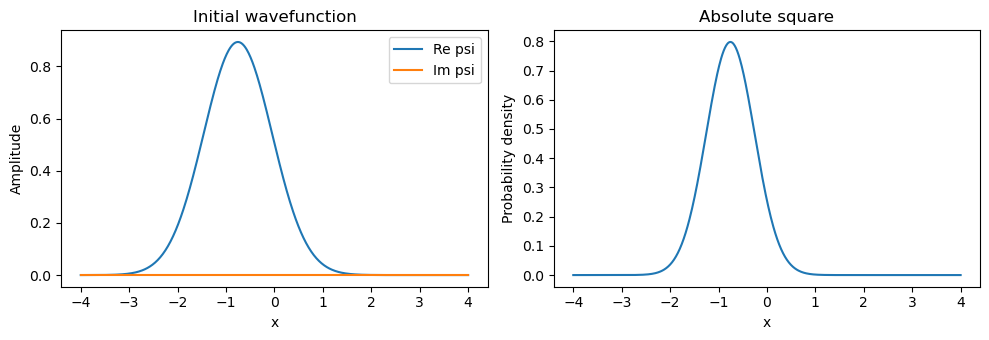

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(x, psi0.real, label="Re psi")
axes[0].plot(x, psi0.imag, label="Im psi")
axes[0].set(xlabel="x", ylabel="Amplitude", title="Initial wavefunction")
axes[0].legend()
axes[1].plot(x, P0)
axes[1].set(xlabel="x", ylabel="Probability density", title="Absolute square")
fig.tight_layout()
plt.show()

In [5]:
def free_kernel(x_destination, x_source, step): #using m = omega = hbar = 1
    return (
        (2*np.pi*1j*np.sin(step))**(-1/2) * np.exp(1j/(2*np.sin(step)) * ((x_destination**2 + x_source**2) * np.cos(step)-2*x_destination*x_source))
    )

K_step = free_kernel(x[:, None], x[None, :], dt)
print("Destination column:", x[:, None].shape)
print("Source row:", x[None, :].shape)
print("Kernel:", K_step.shape, K_step.dtype)

Destination column: (601, 1)
Source row: (1, 601)
Kernel: (601, 601) complex128


In [6]:
U = dx * K_step
K8_free = np.linalg.matrix_power(U, 8) / dx
print(K8_free)  # NumPy truncates large arrays automatically.

# These must be the same evolution of the initial state.
psi_after_8 = np.linalg.matrix_power(U, 8) @ psi0
print("Eight-step forms agree:", np.allclose(dx * K8_free @ psi0, psi_after_8))

[[-0.05955846+0.0178667j  -0.0757611 +0.0217024j  -0.07967385+0.05414053j
  ... -0.46505982-0.30932634j -0.35439299-0.42735575j
  -0.21687407-0.50917202j]
 [-0.0757611 +0.0217024j  -0.0896081 +0.03330227j -0.08308486+0.06724787j
  ... -0.53404108-0.16837676j -0.46141968-0.31131639j
  -0.35439299-0.42735575j]
 [-0.07967385+0.05414053j -0.08308486+0.06724787j -0.06226964+0.09303051j
  ... -0.56407376-0.01040964j -0.53404108-0.16837676j
  -0.46505982-0.30932634j]
 ...
 [-0.46505982-0.30932634j -0.53404108-0.16837676j -0.56407376-0.01040964j
  ... -0.06226964+0.09303051j -0.08308486+0.06724787j
  -0.07967385+0.05414053j]
 [-0.35439299-0.42735575j -0.46141968-0.31131639j -0.53404108-0.16837676j
  ... -0.08308486+0.06724787j -0.0896081 +0.03330227j
  -0.0757611 +0.0217024j ]
 [-0.21687407-0.50917202j -0.35439299-0.42735575j -0.46505982-0.30932634j
  ... -0.07967385+0.05414053j -0.0757611 +0.0217024j
  -0.05955846+0.0178667j ]]
Eight-step forms agree: True


In [7]:
# B Starts Here

In [8]:
def evolve(U, initial_state, steps):
    states = np.empty((steps + 1, initial_state.size), dtype=complex)
    states[0] = initial_state
    for n in range(steps):
        states[n + 1] = U @ states[n]
    return states

psi = evolve(U, psi0, NT)
P = np.abs(psi)**2
norm = dx * np.sum(P, axis=1)
x_mean = dx * np.sum(P * x[None, :], axis=1)
print("States:", psi.shape, "Mean positions:", x_mean.shape)

States: (129, 601) Mean positions: (129,)


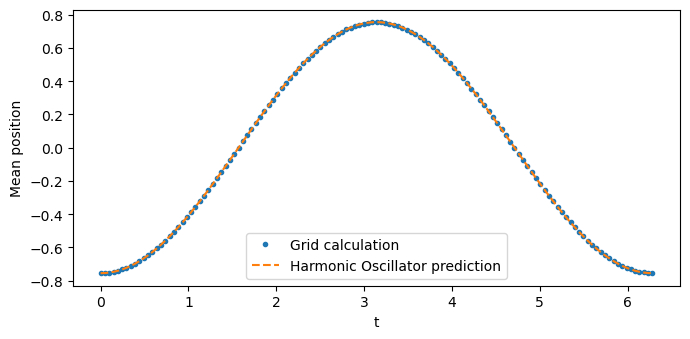

In [9]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(t, x_mean, "o", markersize=3, label="Grid calculation")
ax.plot(t, center*np.cos(t), "--", label="Harmonic Oscillator prediction")
ax.set(xlabel="t", ylabel="Mean position")
ax.legend()
fig.tight_layout()
plt.show()

In [10]:
# C Starts Here

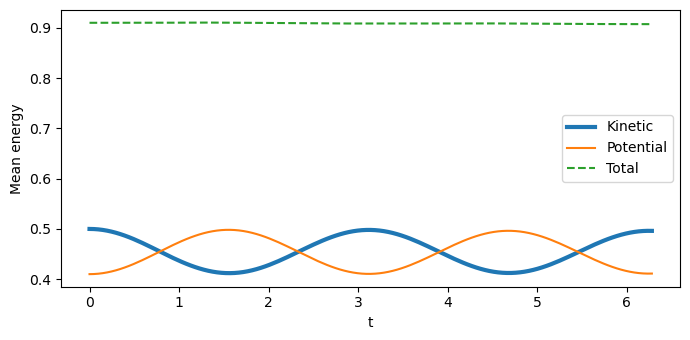

In [11]:
dpsi_dx = np.gradient(psi, dx, axis=1, edge_order=2)
V_grid = 0.5*x**2
K_mean = 0.5 * dx * np.sum(np.abs(dpsi_dx)**2, axis=1)
V_mean = dx * np.sum(P * V_grid[None, :], axis=1)
E_mean = K_mean + V_mean

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(t, K_mean, label="Kinetic", linewidth=3)
ax.plot(t, V_mean, label="Potential")
ax.plot(t, E_mean, "--", label="Total")
ax.set(xlabel="t", ylabel="Mean energy")
ax.legend()
fig.tight_layout()
plt.show()

In [12]:
# D Starts Here

In [13]:
snapshot_indices = 8 * np.arange(9)
snapshot_times = t[snapshot_indices]
P_snapshots = P[snapshot_indices]
print("Indices:", snapshot_indices)
print("Times:", snapshot_times)
print("Density snapshots:", P_snapshots.shape)

Indices: [ 0  8 16 24 32 40 48 56 64]
Times: [0.         0.39269908 0.78539816 1.17809725 1.57079633 1.96349541
 2.35619449 2.74889357 3.14159265]
Density snapshots: (9, 601)


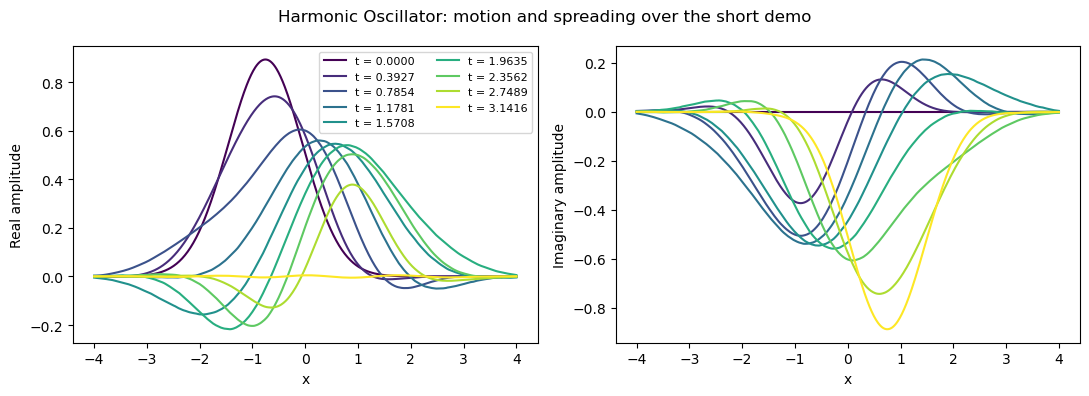

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True)
colors = plt.cm.viridis(np.linspace(0, 1, len(snapshot_indices)))
for index, color in zip(snapshot_indices, colors):
    label = f"t = {t[index]:.4f}"
    axes[0].plot(x, psi[index].real, color=color, label=label)
    axes[1].plot(x, psi[index].imag, color=color)
axes[0].set(xlabel="x", ylabel="Real amplitude")
# axes[0].plot(x, V_grid, color=color, label=label)
# axes[0].plot(x, P, color=color, label=label)
axes[1].set(xlabel="x", ylabel="Imaginary amplitude")
axes[0].legend(fontsize=8, ncol=2)
fig.suptitle("Harmonic Oscillator: motion and spreading over the short demo")
fig.tight_layout()
plt.show()

In [15]:
# E Starts Here

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
real_line, = axes[0].plot(x, psi[0].real, label="Re psi")
imag_line, = axes[0].plot(x, psi[0].imag, label="Im psi")
density_line, = axes[1].plot(x, P[0])
amplitude_limit = 1.1 * np.max(np.abs(psi))
axes[0].set(xlim=(x[0], x[-1]), ylim=(-amplitude_limit, amplitude_limit),
            xlabel="x", ylabel="Amplitude")
axes[0].legend(loc="upper right")
axes[1].set(xlim=(x[0], x[-1]), ylim=(0, 1.1 * P.max()),
            xlabel="x", ylabel="Probability density")
time_label = fig.suptitle("")
fig.tight_layout(rect=(0, 0, 1, 0.9))

def update_frame(n):
    real_line.set_ydata(psi[n].real)
    imag_line.set_ydata(psi[n].imag)
    density_line.set_ydata(P[n])
    time_label.set_text(f"Free particle: t = {t[n]:.4f}; norm = {norm[n]:.6f}")
    return real_line, imag_line, density_line, time_label

animation = FuncAnimation(fig, update_frame, frames=len(t), interval=1000 / 6)
gif_path = Path("harmonic_oscillator_demo.gif")
animation.save(gif_path, writer=PillowWriter(fps=6), dpi=80)
plt.close(fig)
print("Saved:", gif_path.resolve(), "with", len(t), "frames")

Saved: /home/imacdonell/phys142/assignments/assignment1/harmonic_oscillator_demo.gif with 129 frames


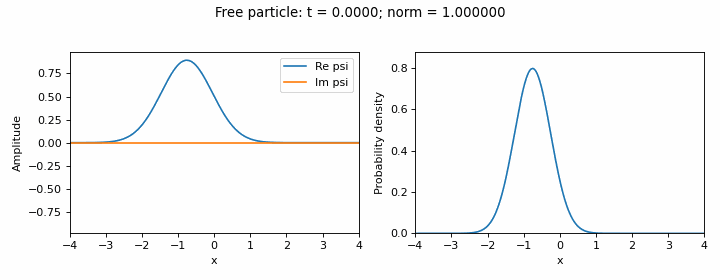

In [17]:
display(Image(filename=str(gif_path)))

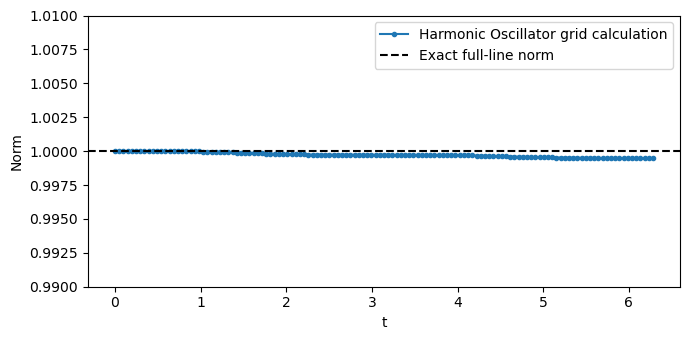

In [18]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(t, norm, "o-", markersize=3, label="Harmonic Oscillator grid calculation")
ax.axhline(1, color="black", linestyle="--", label="Exact full-line norm")
ax.set(xlabel="t", ylabel="Norm", ylim=(0.99, 1.01))
ax.legend()
fig.tight_layout()
plt.show()

In [19]:
# F Starts Here

In [20]:
# Writing Assignment JSON

In [21]:
def assignment_results(tsn, x_start, K8eps, x_mean, V, K, E, P_snapshots):
    if not np.isclose(x_start, center_from_tsn(tsn), rtol=0, atol=1e-12):
        raise ValueError("x_start does not match the TSN.")
    expected = {
        "K8eps": (K8eps, (601, 601)),
        "x_mean": (x_mean, (129,)),
        "V": (V, (129,)), "K": (K, (129,)), "E": (E, (129,)),
        "P": (P_snapshots, (9, 601)),
    }
    arrays = {}
    for name, (values, shape) in expected.items():
        values = np.asarray(values)
        if values.shape != shape or not np.isfinite(values).all():
            raise ValueError(f"{name} must have shape {shape} and contain finite values.")
        if name != "K8eps" and np.iscomplexobj(values):
            raise ValueError(f"{name} must contain real values.")
        arrays[name] = values
    if np.any(arrays["P"] < 0):
        raise ValueError("P must be a nonnegative probability density.")
    row = arrays["K8eps"][300]
    return {
        "tsn": tsn, "x_start": float(x_start),
        "K8eps_row": {"re": row.real.tolist(), "im": row.imag.tolist()},
        "x_mean": arrays["x_mean"].tolist(),
        "V": arrays["V"].tolist(), "K": arrays["K"].tolist(), "E": arrays["E"].tolist(),
        "P": arrays["P"].tolist(),
    }

In [22]:
def center_from_tsn(tsn):
    if (not isinstance(tsn, str) or len(tsn) != 9
            or not tsn.isascii() or not tsn.isdigit() or not tsn.startswith("2")):
        raise ValueError("TSN must be a string of nine digits starting with 2.")
    d = int(tsn[-2:])
    s = int(tsn[-3])
    return (-1)**s * (0.5 + d / 200)

In [23]:
practice = {"model": "free particle", "t": t.tolist(), "norm": norm.tolist()}
practice_path = Path("free_particle_practice.json")
with practice_path.open("w") as f:
    json.dump(practice, f, indent=2, allow_nan=False)
with practice_path.open() as f:
    loaded_practice = json.load(f)
print(loaded_practice["model"], "saved times:", len(loaded_practice["t"]))

free particle saved times: 129


In [24]:
tsn = "200329351"
x_start = center_from_tsn(tsn)
# Build your initial state with this x_start before propagating it.

results = assignment_results(
    tsn, x_start, K8_free, x_mean,
    V_mean, K_mean, E_mean, P[8 * np.arange(9)],
)
with open("results.json", "w") as f:
    json.dump(results, f, indent=2, allow_nan=False)

with open("results.json") as f:
    saved = json.load(f)
print("Saved TSN:", saved["tsn"])
print("Snapshot dimensions:", np.asarray(saved["P"]).shape)

Saved TSN: 200329351
Snapshot dimensions: (9, 601)
